<a href="https://colab.research.google.com/github/gaikwadritik741-sys/MDM-ML/blob/main/Machine_Predictive_Maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [ ]:
df = pd.read_csv("predictive_maintenance.csv")

Explore the data

In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Target"].value_counts())

print("\nSummary statistics:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]   

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


Visualize machine failures

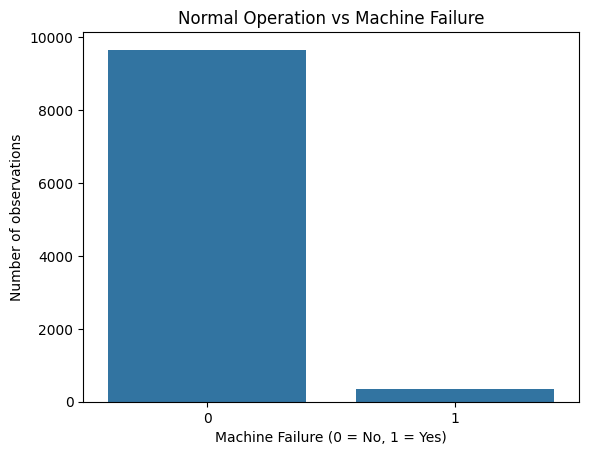

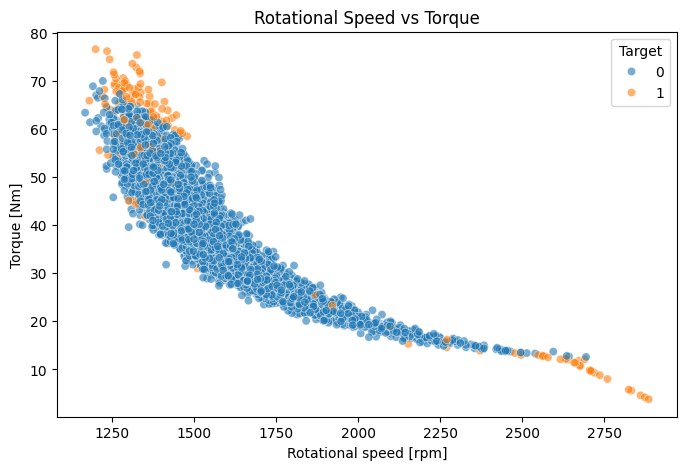

In [ ]:
sns.countplot(data=df, x="Target")
plt.title("Normal Operation vs Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of observations")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Target",
    alpha=0.6
)
plt.title("Rotational Speed vs Torque")
plt.show()

Correlation heatmap

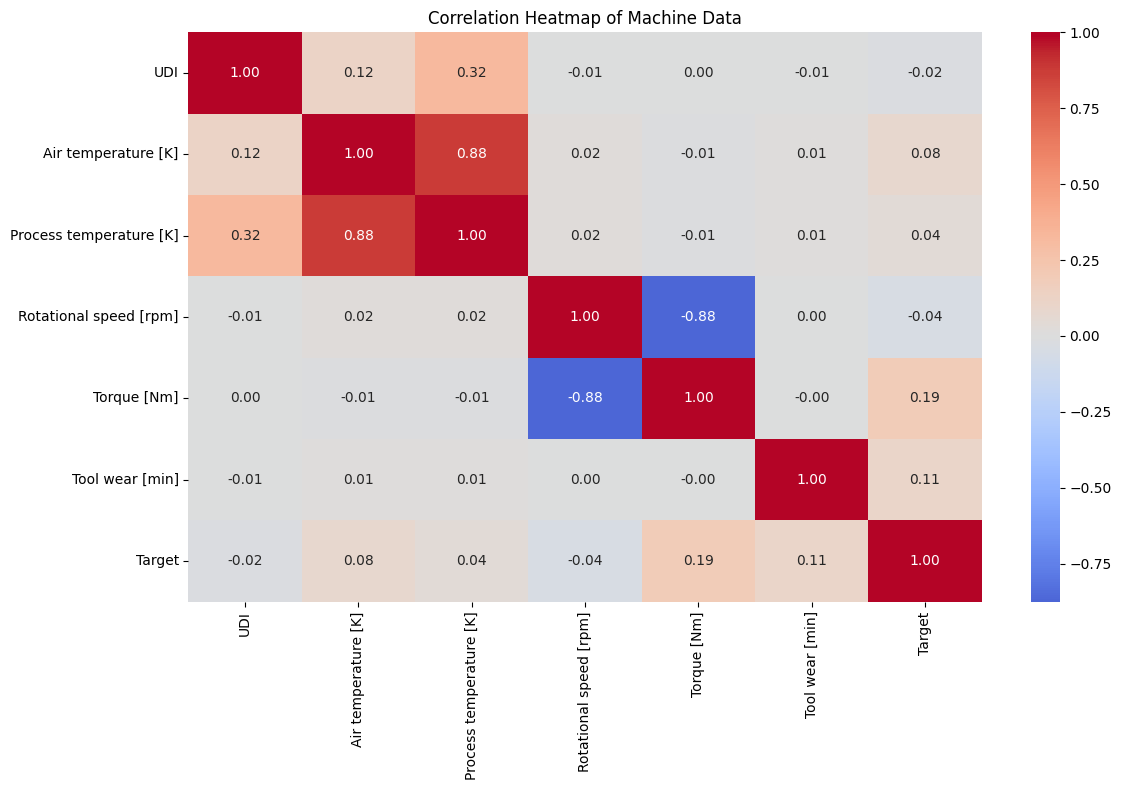

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Machine Data")
plt.tight_layout()
plt.show()

Rotational speed vs machine failure — Box Plot

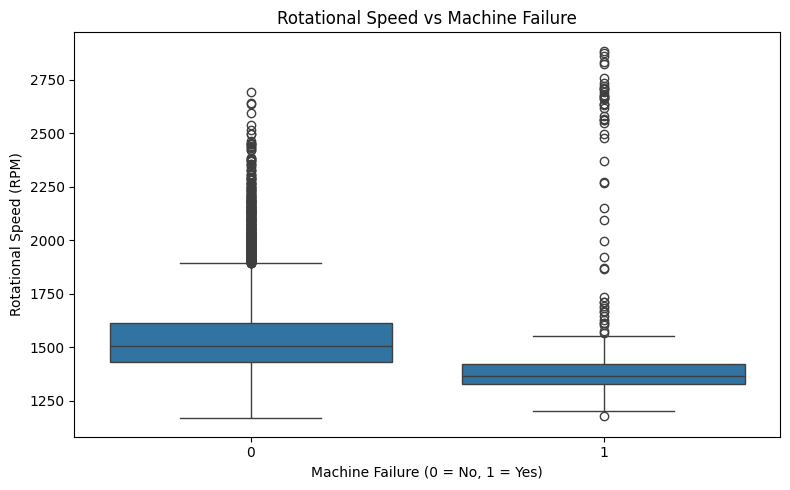

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Rotational speed [rpm]"
)

plt.title("Rotational Speed vs Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Rotational Speed (RPM)")
plt.tight_layout()
plt.show()

Machine failure percentage — Pie Chart

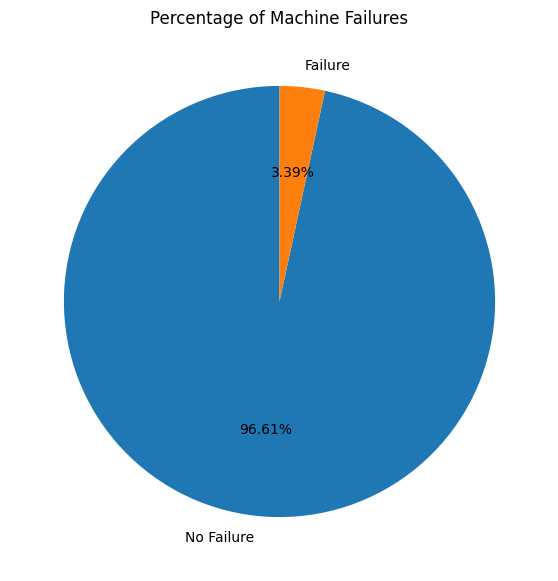

In [ ]:
failure_counts = df["Target"].value_counts().sort_index()

plt.figure(figsize=(7, 7))
plt.pie(
    failure_counts,
    labels=["No Failure", "Failure"],
    autopct="%1.2f%%",
    startangle=90
)
plt.title("Percentage of Machine Failures")
plt.show()

Feature engineering

In [ ]:
import pandas as pd
import numpy as np
# Make a copy of the original dataset
df_fe = df.copy()

# 1. Temperature difference
df_fe["Temperature Difference"] = (
    df_fe["Process temperature [K]"]
    - df_fe["Air temperature [K]"]
)

# 2. Temperature ratio
df_fe["Temperature Ratio"] = (
    df_fe["Process temperature [K]"]
    / df_fe["Air temperature [K]"].replace(0, np.nan)
)

# 3. Mechanical power proxy: speed x torque
# This is a proxy, not actual power in watts
df_fe["Power Proxy"] = (
    df_fe["Rotational speed [rpm]"]
    * df_fe["Torque [Nm]"]
)

# 4. Torque-to-speed ratio
df_fe["Torque Speed Ratio"] = (
    df_fe["Torque [Nm]"]
    / df_fe["Rotational speed [rpm]"].replace(0, np.nan)
)


Prepare the data for machine learning

In [ ]:
# Input features available before the failure outcome
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_columns].copy()
y = df["Target"].copy()

# Separate categorical and numerical features
categorical_features = ["Type"]
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Encode product type and pass numerical values through unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("category", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numbers", "passthrough", numerical_features)
    ]
)

# Keep the original failure ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training data prepared!")

Training records: 8000
Testing records: 2000
Training data prepared!


Train four machine learning algorithms

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Support Vector Machine": SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

trained_models = {}

for name, algorithm in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Support Vector Machine trained successfully!


Evaluate all four models

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(
    results_df.sort_values("F1 Score", ascending=False)
    .round(4)
)


,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Decision Tree,0.9785,0.7273,0.5882,0.6504,0.7902
2,Random Forest,0.9800,0.9375,0.4412,0.6000,0.9587
0,Logistic Regression,0.8270,0.1436,0.8235,0.2445,0.9069
3,Support Vector Machine,0.7840,0.1240,0.8824,0.2174,0.9029


Compare the models using graphs

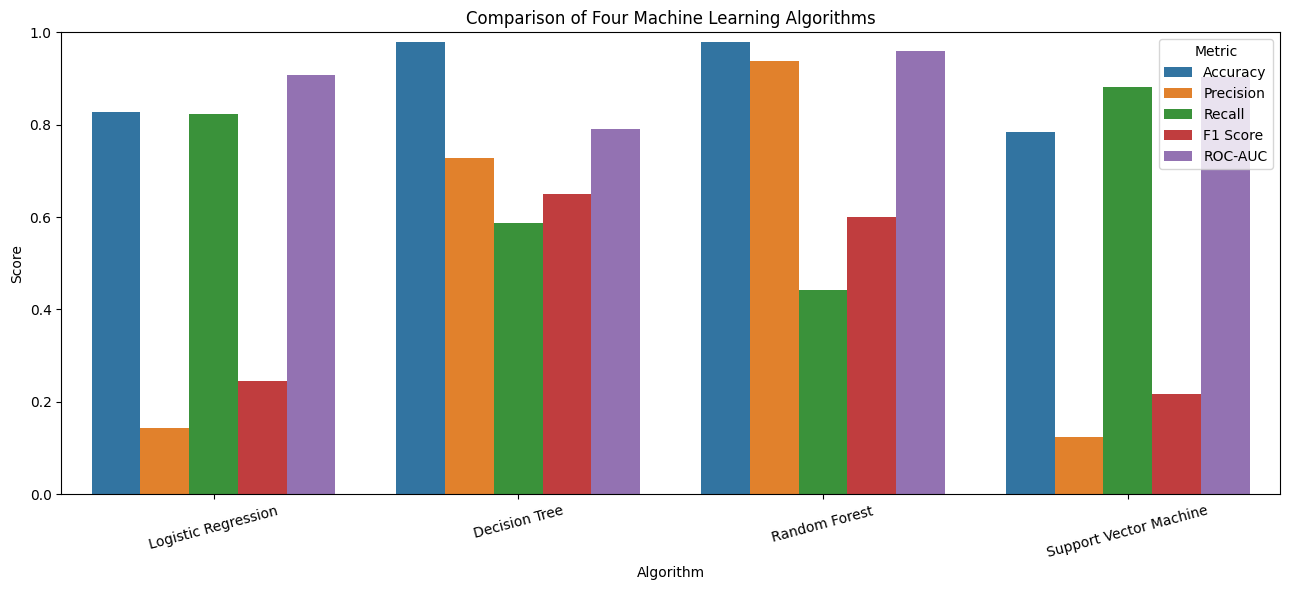

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_long = results_df.melt(
    id_vars="Algorithm",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=results_long,
    x="Algorithm",
    y="Score",
    hue="Metric"
)
plt.title("Comparison of Four Machine Learning Algorithms")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


Confusion matrices for all models

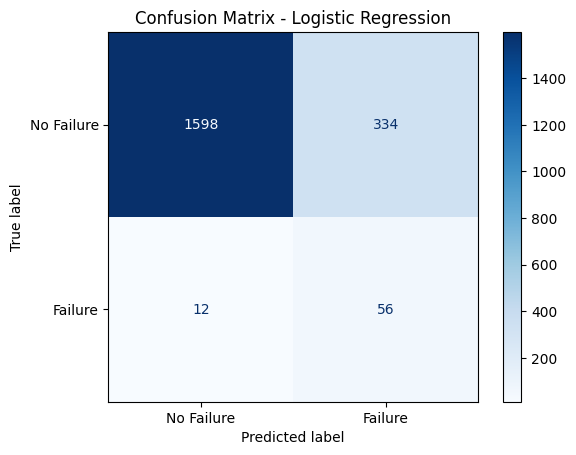

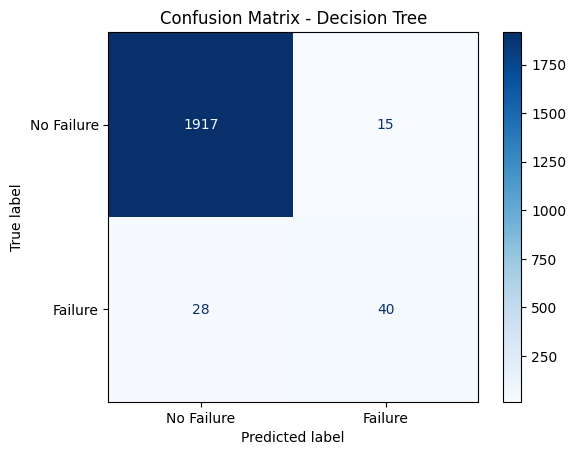

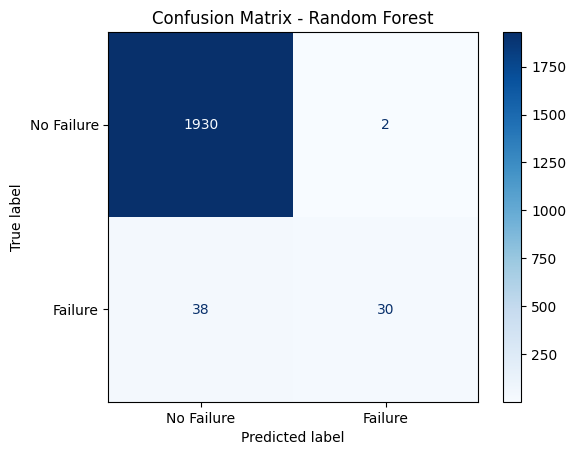

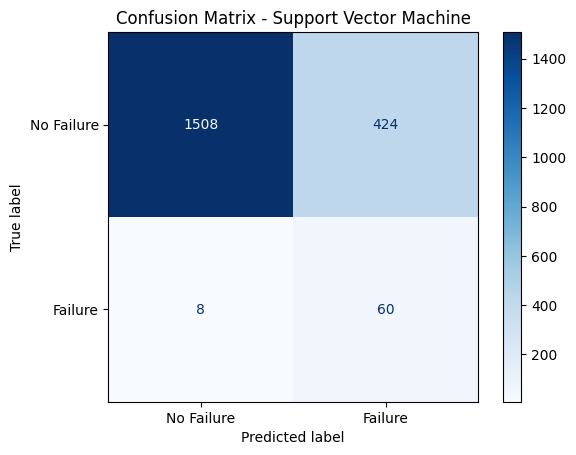

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No Failure", "Failure"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()


Select the best model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Automatically rebuild results_df if it was lost in a session restart
if "results_df" not in globals():
    results = []
    for name, model in trained_models.items():
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        results.append({
            "Algorithm": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1 Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob)
        })
    results_df = pd.DataFrame(results)

best_row = results_df.loc[results_df["F1 Score"].idxmax()]
best_name = best_row["Algorithm"]
best_model = trained_models[best_name]

print("Best model by F1-score:", best_name)
print(best_row.to_string())

print("\nClassification report:")
print(classification_report(
    y_test,
    best_model.predict(X_test),
    labels=[0, 1],
    target_names=["No Failure", "Failure"],
    zero_division=0
))

Best model by F1-score: Decision Tree
Algorithm    Decision Tree
Accuracy            0.9785
Precision         0.727273
Recall            0.588235
F1 Score          0.650407
ROC-AUC           0.790236

Classification report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.73      0.59      0.65        68

    accuracy                           0.98      2000
   macro avg       0.86      0.79      0.82      2000
weighted avg       0.98      0.98      0.98      2000



,Feature,Importance
5,numbers__Rotational speed [rpm],0.339227
6,numbers__Torque [Nm],0.315015
7,numbers__Tool wear [min],0.256251
3,numbers__Air temperature [K],0.044936
4,numbers__Process temperature [K],0.030377
1,category__Type_L,0.008990
2,category__Type_M,0.004421
0,category__Type_H,0.000784


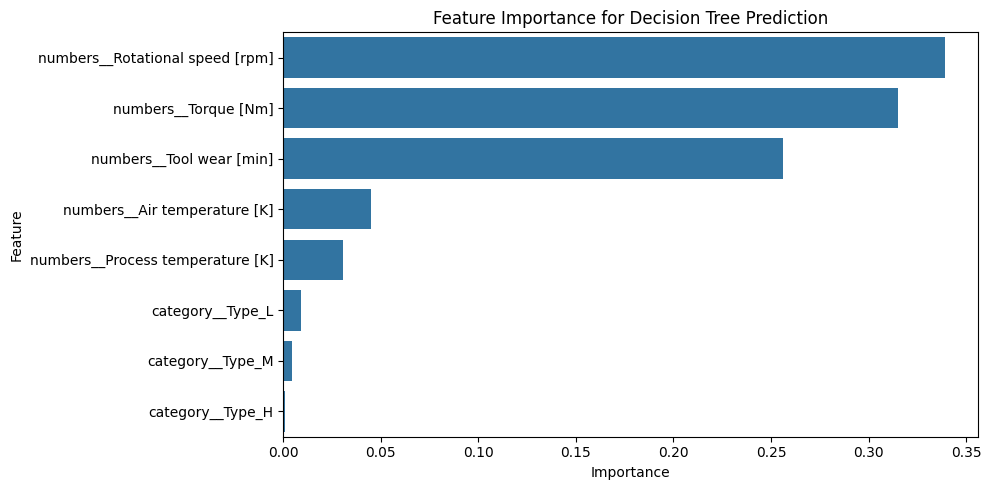

In [ ]:
rf = best_model.named_steps["model"]
encoded_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title(f"Feature Importance for {best_name} Prediction")
plt.tight_layout()
plt.show()

Predict failure for a new machine

In [ ]:

new_machine = pd.DataFrame([{
    "Type": "L",
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 40.0,
    "Tool wear [min]": 180
}])

prediction = model.predict(new_machine)[0]
failure_probability = model.predict_proba(new_machine)[0, 1]

print("Predicted result:",
      "FAILURE" if prediction == 1 else "NO FAILURE")
print(f"Model-estimated failure probability: "
      f"{failure_probability:.2%}")


Predicted result: NO FAILURE
Model-estimated failure probability: 1.90%
